# Bestsellers in the Library Canon

**Research question:** Among OCLC's "Top 500 Greatest Novels" (the novels held by the most libraries), which ones were also *New York Times* hardcover fiction bestsellers — and do those bestsellers look different from the rest of the list in **when** they were published, **how Goodreads readers rate them**, and **who wrote them**?

The Top 500 list claims to measure "literary greatness" by library holdings. Commercial success (the NYT list) and online reader response (Goodreads) are two other ways of deciding which books matter. This notebook explores where those three measures overlap and where they disagree.

**Notebook outline**
1. Setup
2. The datasets: where they come from and what one row means
3. Initial audit of each dataset
4. Linking the two datasets (and why the simple merge fails)
5. Coverage and missing-data issues that limit interpretation
6. Visualizations and interpretation
7. Conclusion
8. Sources and credits

## 1. Setup

This notebook needs `pandas` and `altair` (installed with `pip install -r requirements.txt` from the `pandas-eda` folder — see the README). Both datasets are loaded from stable remote URLs, so no local data files are needed.

In [1]:
import pandas as pd
import altair as alt

# Show more columns when printing wide tables
pd.set_option("display.max_columns", 40)

## 2. The datasets

### Top 500 "Greatest" Novels (Responsible Datasets in Context)

- **Provenance:** In 2019 OCLC (the non-profit that runs WorldCat, the largest database of library catalog records) published a list of the 500 novels held by the most libraries. Anna Preus and Aashna Sheth expanded that list with data from VIAF (author information), Wikipedia (publication year), Goodreads (ratings), and Project Gutenberg (full texts), and published it on the [Responsible Datasets in Context](https://www.responsible-datasets-in-context.com/posts/top-500-novels/top-500-novels.html) site.
- **One row = one novel** on OCLC's Top 500 list, with its library holdings, author information, and Goodreads statistics.
- We use the version *without* full texts (the full-text version is ~152 MB and is not needed here).

### New York Times Hardcover Fiction Bestsellers, 1931–2020 (Post45 Data Collective)

- **Provenance:** Compiled by Jordan Pruett and published by the [Post45 Data Collective](https://data.post45.org/nyt-fiction-bestsellers-data/). It records the full weekly NYT hardcover fiction list from its start in 1931 through 2020.
- **One row = one book in one position on one week's list.** A book that stayed on the list for 20 weeks appears in 20 rows.

In [2]:
NOVELS_URL = "https://raw.githubusercontent.com/melaniewalsh/responsible-datasets-in-context/main/datasets/top-500-novels/final_merged_dataset_no_full_text.tsv"
NYT_URL = "https://raw.githubusercontent.com/ecds/post45-datasets/main/nyt_full.tsv"

# Both files are tab-separated, so we pass sep="\t"
novels_df = pd.read_csv(NOVELS_URL, sep="\t", encoding="utf-8")
nyt_df = pd.read_csv(NYT_URL, sep="\t", encoding="utf-8")

## 3. Initial audit

### 3a. Top 500 novels

In [3]:
novels_df.head()

,top_500_rank,title,author,pub_year,orig_lang,genre,author_birth,author_death,author_gender,author_primary_lang,author_nationality,author_field_of_activity,author_occupation,oclc_holdings,oclc_eholdings,oclc_total_editions,oclc_holdings_rank,oclc_editions_rank,gr_avg_rating,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi,author_viaf,gr_url,wiki_url,pg_eng_url,pg_orig_url
0,1,Don Quixote,Miguel de Cervantes,1605,Spanish,action,1547,1616,male,spa,ES,NaN,"soldiers,poets spanish,novelists spanish,drama...",30840.0,4992.0,9017.0,9.0,1.0,3.90,"269,435","12,053",318,211,1.810748e+09,17220427,https://www.goodreads.com/book/show/3836.Don_Q...,https://en.wikipedia.org/wiki/Don_Quixote,https://www.gutenberg.org/cache/epub/996/pg996...,https://www.gutenberg.org/cache/epub/2000/pg20...
1,2,Alice's Adventures in Wonderland,Lewis Carroll,1865,English,fantasy,1832,1898,male,eng,GB,"writing,teaching,photography,mathematics","authors,teachers,photographers,mathematicians",24125.0,6698.0,2694.0,18.0,33.0,4.06,"561,016","15,380",172,133,1.156132e+10,66462036,https://www.goodreads.com/book/show/24213.Alic...,https://en.wikipedia.org/wiki/Alice%27s_Advent...,https://www.gutenberg.org/cache/epub/11/pg11.txt,NaN
2,3,The Adventures of Huckleberry Finn,Mark Twain,1884,English,action,1835,1910,male,eng,US,"wit and humor,literature,humor","lecturers,humorists,authors",32602.0,11783.0,4119.0,6.0,6.0,3.83,"1,262,480","19,440",373,68,3.373178e+09,50566653,https://www.goodreads.com/book/show/2956.The_A...,https://en.wikipedia.org/wiki/Adventures_of_Hu...,https://www.gutenberg.org/cache/epub/76/pg76.txt,NaN
3,4,The Adventures of Tom Sawyer,Mark Twain,1876,English,action,1835,1910,male,eng,US,"wit and humor,literature,humor","lecturers,humorists,authors",32602.0,11783.0,4119.0,7.0,7.0,3.92,"931,898","13,603",301,88,3.373178e+09,50566653,https://www.goodreads.com/book/show/24583.The_...,https://en.wikipedia.org/wiki/The_Adventures_o...,https://www.gutenberg.org/cache/epub/74/pg74.txt,NaN
4,5,Treasure Island,Robert Louis Stevenson,1883,English,action,1850,1894,male,eng,GB,NaN,"travel writers,poets,novelists",37702.0,14286.0,5555.0,1.0,2.0,3.84,"486,155","16,307",368,145,3.434000e+03,95207986,https://www.goodreads.com/book/show/295.Treasu...,https://en.wikipedia.org/wiki/Treasure_Island,https://www.gutenberg.org/cache/epub/120/pg120...,NaN


In [4]:
# (rows, columns)
novels_df.shape

(500, 29)

In [5]:
novels_df.dtypes

top_500_rank                  int64
title                        object
author                       object
pub_year                      int64
orig_lang                    object
genre                        object
author_birth                 object
author_death                 object
author_gender                object
author_primary_lang          object
author_nationality           object
author_field_of_activity     object
author_occupation            object
oclc_holdings               float64
oclc_eholdings              float64
oclc_total_editions         float64
oclc_holdings_rank          float64
oclc_editions_rank          float64
gr_avg_rating               float64
gr_num_ratings               object
gr_num_reviews               object
gr_avg_rating_rank            int64
gr_num_ratings_rank           int64
oclc_owi                    float64
author_viaf                  object
gr_url                       object
wiki_url                     object
pg_eng_url                  

`gr_num_ratings` and `gr_num_reviews` are stored as text (`object`) because the numbers contain commas (e.g. `"1,262,480"`). We convert them to integers so we can do math and plot them.

In [6]:
for col in ["gr_num_ratings", "gr_num_reviews"]:
    novels_df[col] = novels_df[col].str.replace(",", "").astype(int)

novels_df[["gr_num_ratings", "gr_num_reviews"]].dtypes

gr_num_ratings    int64
gr_num_reviews    int64
dtype: object

In [7]:
novels_df.describe()

,top_500_rank,pub_year,oclc_holdings,oclc_eholdings,oclc_total_editions,oclc_holdings_rank,oclc_editions_rank,gr_avg_rating,gr_num_ratings,gr_num_reviews,gr_avg_rating_rank,gr_num_ratings_rank,oclc_owi
count,500.000000,500.000000,495.000000,495.000000,495.000000,495.000000,495.000000,500.000000,5.000000e+02,500.000000,500.000000,500.000000,4.950000e+02
mean,250.500000,1932.132000,10401.438384,2218.593939,896.642424,248.000000,248.000000,3.971440,6.035750e+05,18958.936000,250.500000,250.500000,1.602208e+09
std,144.481833,84.306546,5694.509003,3084.595715,1019.015572,143.038456,143.038456,0.227688,1.094771e+06,28422.988512,144.481833,144.481833,2.675299e+09
min,1.000000,1021.000000,996.000000,25.000000,21.000000,1.000000,1.000000,3.290000,2.200000e+01,2.000000,1.000000,1.000000,1.040000e+03
25%,125.750000,1900.000000,6800.000000,352.000000,241.000000,124.500000,124.500000,3.830000,6.122675e+04,2803.750000,125.750000,125.750000,3.972875e+05
50%,250.500000,1948.000000,8318.000000,558.000000,485.000000,248.000000,248.000000,3.980000,1.843000e+05,7945.000000,250.500000,250.500000,1.675603e+07
75%,375.250000,1989.000000,12184.000000,3223.000000,1207.500000,371.500000,371.500000,4.120000,6.232955e+05,21732.750000,375.250000,375.250000,2.830459e+09
max,500.000000,2015.000000,37702.000000,15545.000000,9017.000000,495.000000,495.000000,4.620000,9.977698e+06,216829.000000,500.000000,500.000000,1.239276e+10


In [8]:
# Count of missing (NaN) values per column, largest first
novels_df.isna().sum().sort_values(ascending=False)

pg_orig_url                 436
author_field_of_activity    171
author_occupation            41
gr_url                       20
oclc_owi                      5
oclc_editions_rank            5
oclc_holdings_rank            5
oclc_total_editions           5
oclc_holdings                 5
oclc_eholdings                5
author_death                  4
author_birth                  1
author_nationality            0
gr_avg_rating_rank            0
pg_eng_url                    0
wiki_url                      0
author                        0
author_viaf                   0
pub_year                      0
gr_num_ratings_rank           0
gr_num_ratings                0
gr_num_reviews                0
author_primary_lang           0
gr_avg_rating                 0
orig_lang                     0
genre                         0
title                         0
author_gender                 0
top_500_rank                  0
dtype: int64

`isna()` says the `genre` column has **no** missing values — but that is misleading. Missing genres were recorded as the text `"na"`, which pandas does not recognize as missing:

In [9]:
novels_df["genre"].value_counts()

genre
na            221
history        53
fantasy        48
romance        33
bildung        27
scifi          21
thrillers      21
mystery        18
action         16
political      15
horror          8
autobio         8
allegories      7
war             4
Name: count, dtype: int64

In [10]:
# Treat the "na" placeholder as a real missing value
novels_df["genre"] = novels_df["genre"].replace("na", pd.NA)
print("Novels with no genre:", novels_df["genre"].isna().sum(), "of", len(novels_df))

Novels with no genre: 221 of 500


### 3b. NYT bestsellers

In [11]:
nyt_df.head()

,year,week,rank,title_id,title,author
0,1931,1931-10-12,1,6477,THE TEN COMMANDMENTS,Warwick Deeping
1,1931,1931-10-12,2,1808,FINCHE'S FORTUNE,Mazo de la Roche
2,1931,1931-10-12,3,5304,THE GOOD EARTH,Pearl S. Buck
3,1931,1931-10-12,4,4038,SHADOWS ON THE ROCK,Willa Cather
4,1931,1931-10-12,5,3946,SCARMOUCHE THE KING MAKER,Rafael Sabatini


In [12]:
print("shape:", nyt_df.shape)
nyt_df.dtypes

shape: (60386, 6)


year         int64
week        object
rank         int64
title_id     int64
title       object
author      object
dtype: object

In [13]:
nyt_df.describe()

,year,rank,title_id
count,60386.000000,60386.000000,60386.000000
mean,1980.291375,7.578329,3810.020154
std,24.440366,4.401472,2118.650219
min,1931.000000,1.000000,0.000000
25%,1958.000000,4.000000,2012.000000
50%,1982.000000,7.000000,3931.500000
75%,2001.000000,11.000000,5599.000000
max,2020.000000,18.000000,7430.000000


In [14]:
nyt_df.isna().sum()

year         0
week         0
rank         0
title_id     0
title        0
author      10
dtype: int64

In [15]:
print("Unique titles on the list:", nyt_df["title_id"].nunique())
print("Weeks covered:", nyt_df["week"].min(), "to", nyt_df["week"].max())

Unique titles on the list: 7431
Weeks covered: 1931-10-12 to 2020-12-06


## 4. Linking the two datasets

To ask which Top 500 novels were bestsellers, we need to match rows across the datasets. The only shared columns are `title` and `author`.

### 4a. The simple approach from class

In class we capitalized the NYT titles (they are stored in ALL CAPS) and merged on title + author:

In [16]:
nyt_capitalized = nyt_df["title"].str.capitalize()
simple_matches = novels_df["title"].isin(nyt_capitalized).sum()
print("Top 500 titles found with .str.capitalize():", simple_matches)

Top 500 titles found with .str.capitalize(): 12


Only a handful match, because `.capitalize()` only uppercases the *first* letter (`"The grapes of wrath"`) while the Top 500 list uses title case (`"The Grapes of Wrath"`). Punctuation and leading articles also differ between the two sources.

### 4b. A more careful match

To compare titles fairly, we build a simplified **matching key** for each title:
1. remove accents (`García` → `Garcia`),
2. lowercase everything,
3. remove punctuation,
4. remove a leading "the", "a", or "an".

In [17]:
def make_key(text):
    """Simplify a column of titles or names so the two datasets can be compared."""
    return (
        text.str.normalize("NFKD")                     # split letters from their accents
        .str.encode("ascii", errors="ignore")          # drop the accent marks
        .str.decode("ascii")
        .str.lower()
        .str.replace(r"[^a-z0-9 ]", "", regex=True)    # drop punctuation
        .str.replace(r"^(the|a|an) ", "", regex=True)  # drop a leading article
        .str.strip()
    )

# Quick check of what the function does
make_key(pd.Series(["The Grapes of Wrath", "THE GRAPES OF WRATH", "Cien años: A Test!"]))

0     grapes of wrath
1     grapes of wrath
2    cien anos a test
dtype: object

Matching on title alone is not enough: different authors can write books with the same title (*The Stranger* by Albert Camus vs. *The Stranger* by Harlan Coben). Author names also vary ("J.K. Rowling" vs. "J. K. Rowling", or co-authored James Patterson books), so we require that the Top 500 author's **last name** appears somewhere in the NYT author field.

First, we collapse the weekly NYT data to **one row per bestselling title**, keeping how many weeks it spent on the list, its best (lowest) rank, and the first year it appeared.

In [18]:
nyt_titles = (
    nyt_df.groupby("title_id")
    .agg(
        nyt_title=("title", "first"),
        nyt_author=("author", "first"),
        nyt_weeks=("week", "count"),       # each row is one week on the list
        nyt_best_rank=("rank", "min"),
        nyt_first_year=("year", "min"),
    )
    .reset_index()
)
nyt_titles["title_key"] = make_key(nyt_titles["nyt_title"])
nyt_titles["author_key"] = make_key(nyt_titles["nyt_author"].fillna(""))

nyt_titles.head()

,title_id,nyt_title,nyt_author,nyt_weeks,nyt_best_rank,nyt_first_year,title_key,author_key
0,0,"""H"" IS FOR HOMICIDE",Sue Grafton,15,2,1991,h is for homicide,sue grafton
1,1,"""I"" IS FOR INNOCENT",Sue Grafton,11,2,1992,i is for innocent,sue grafton
2,2,"""J"" IS FOR JUDGMENT",Sue Grafton,10,3,1993,j is for judgment,sue grafton
3,3,"""K"" IS FOR KILLER",Sue Grafton,9,2,1994,k is for killer,sue grafton
4,4,"""L"" IS FOR LAWLESS",Sue Grafton,7,1,1995,l is for lawless,sue grafton


In [19]:
novels_df["title_key"] = make_key(novels_df["title"])
novels_df["author_last"] = make_key(novels_df["author"]).str.split().str[-1]

# Pair every Top 500 novel with every NYT title that has the same title key
candidates = novels_df[["top_500_rank", "title", "author", "title_key", "author_last"]].merge(
    nyt_titles, on="title_key", how="inner"
)

# Keep a pair only if the Top 500 author's last name appears in the NYT author field
candidates["same_author"] = candidates.apply(
    lambda row: row["author_last"] in row["author_key"], axis=1
)
print("Title-only candidate pairs:", len(candidates))
print("Pairs where the author also matches:", candidates["same_author"].sum())

Title-only candidate pairs: 158
Pairs where the author also matches: 147


In [20]:
# Title matches we rejected because the author is different
candidates[~candidates["same_author"]][["title", "author", "nyt_title", "nyt_author"]]

,title,author,nyt_title,nyt_author
9,The Stranger,Albert Camus,THE STRANGER,Harlan Coben
10,The Trial,Franz Kafka,TRIAL,Don M. Mankiewicz
16,The Jungle,Upton Sinclair,THE JUNGLE,Clive Cussler with Jack Du Brul
25,Beloved,Toni Morrison,BELOVED,Viña Delmar
41,The Invisible Man,H.G. Wells,INVISIBLE MAN,Ralph Ellison
132,The Fall,Albert Camus,FALL,Neal Stephenson
134,The Fall,Albert Camus,THE FALL,Guillermo del Toro and Chuck Hogan
142,The Wedding,Nicholas Sparks,THE WEDDING,Danielle Steel
143,The Wedding,Nicholas Sparks,THE WEDDING,Julie Garwood
150,The Heart of the Matter,Graham Greene,HEART OF THE MATTER,Emily Giffin


Every rejected pair is a genuinely different book that happens to share a title (*Beloved* by Toni Morrison vs. *Beloved* by Viña Delmar, *The Stranger* by Camus vs. Coben), so the author check is doing its job.

A novel can match more than one NYT `title_id` (for example if the NYT listed it twice under slightly different records), so we add those weeks together, giving one row per Top 500 novel. Then we left-merge onto the Top 500 data so every novel is kept; novels that were never on the list get `NaN` for the NYT columns.

In [21]:
matches = (
    candidates[candidates["same_author"]]
    .groupby("top_500_rank")
    .agg(
        nyt_weeks=("nyt_weeks", "sum"),
        nyt_best_rank=("nyt_best_rank", "min"),
        nyt_first_year=("nyt_first_year", "min"),
    )
    .reset_index()
)

combined_df = novels_df.merge(matches, on="top_500_rank", how="left")
combined_df["nyt_status"] = combined_df["nyt_weeks"].notna().map(
    {True: "NYT bestseller", False: "Never on NYT list"}
)

print("Rows after merge:", len(combined_df), "(should still be 500)")
combined_df["nyt_status"].value_counts()

Rows after merge: 500 (should still be 500)


nyt_status
Never on NYT list    358
NYT bestseller       142
Name: count, dtype: int64

In [22]:
# The longest-running bestsellers among the Top 500
combined_df.nlargest(10, "nyt_weeks")[["title", "author", "pub_year", "nyt_weeks", "nyt_best_rank"]]

,title,author,pub_year,nyt_weeks,nyt_best_rank
87,The Da Vinci Code,Dan Brown,2003,165.0,1.0
394,The Bridges of Madison County,Robert James Waller,1992,164.0,1.0
485,The Caine Mutiny,Herman Wouk,1951,123.0,1.0
205,The Help,Kathryn Stockett,2009,108.0,1.0
333,The Five People You Meet In Heaven,Mitch Albom,2003,100.0,1.0
28,To Kill a Mockingbird,Harper Lee,1960,98.0,2.0
44,Harry Potter and the Sorcerer's Stone,J.K. Rowling,1997,82.0,1.0
323,Gone Girl,Gillian Flynn,2012,80.0,1.0
329,The Girl Who Kicked the Hornet's Nest,Stieg Larsson,2007,79.0,1.0
76,Gone with the Wind,Margaret Mitchell,1936,78.0,1.0


## 5. Coverage and missing-data issues

Several features of these datasets limit what we can conclude:

1. **Time coverage.** The NYT list starts in 1931, but the Top 500 list runs from 1021 to 2015. A novel published in 1850 *cannot* be an NYT bestseller, so comparing bestsellers to the whole list would be unfair. For the comparisons below we keep only novels **published 1931 or later**.
2. **Only one NYT list.** The data covers the *hardcover fiction* list only. Books that sold mainly in paperback, or children's/young-adult books (the NYT created separate children's lists, starting in 2000), will show up as "never on the list" even if they sold enormously. So "Never on NYT list" really means "not found on the hardcover fiction list."
3. **Imperfect matching.** Our match depends on titles and author names being spelled similarly. Translated titles or re-titled books (e.g. *The Hobbit, or, There and Back Again*) can be missed, so the bestseller count is likely a slight **undercount**.
4. **Missing genres.** Hidden as the text `"na"`, genre is missing for a large share of novels, so genre comparisons would rest on an incomplete subset. That is one reason this notebook does not focus on genre.
5. **Binary gender from VIAF.** `author_gender` comes from library authority records (VIAF), which only offer male/female/unknown. It describes how libraries catalog authors, not necessarily how authors identify.

In [23]:
modern_df = combined_df[combined_df["pub_year"] >= 1931].copy()
print("Novels published 1931 or later:", len(modern_df), "of", len(combined_df))
modern_df["nyt_status"].value_counts()

Novels published 1931 or later: 304 of 500


nyt_status
Never on NYT list    163
NYT bestseller       141
Name: count, dtype: int64

(One matched bestseller, *Ulysses* (1922), drops out here because it was published before 1931 — it reached the NYT list in 1934, after its U.S. publication.)

In [24]:
# How many genres are missing in the 1931+ subset, by group?
modern_df.groupby("nyt_status")["genre"].apply(lambda g: g.isna().mean()).round(2)

nyt_status
NYT bestseller       0.38
Never on NYT list    0.41
Name: genre, dtype: float64

### Quick exploratory plot (pandas)

Before building final charts in Altair, a quick pandas histogram shows how the publication years of the 1931+ novels are spread out.

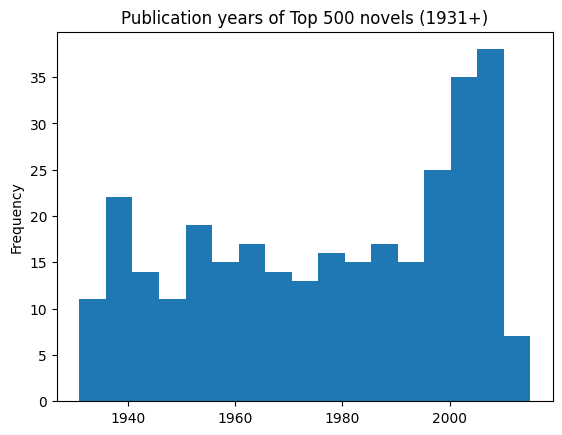

In [25]:
modern_df["pub_year"].plot(kind="hist", bins=17, title="Publication years of Top 500 novels (1931+)");

## 6. Visualizations

Charts are saved as PNG files in the `charts/` folder as well, so they can be viewed on GitHub (GitHub does not display interactive Altair charts inside notebooks).

In [26]:
import os
os.makedirs("charts", exist_ok=True)

# Altair copies the data into every chart, so we keep only the columns the charts use
modern_df["decade"] = (modern_df["pub_year"] // 10) * 10
chart_df = modern_df[[
    "title", "author", "pub_year", "decade", "nyt_status", "nyt_weeks",
    "gr_avg_rating", "gr_num_ratings", "gr_num_ratings_rank", "top_500_rank",
]]

# A consistent color for each group across all charts
status_scale = alt.Scale(domain=["NYT bestseller", "Never on NYT list"], range=["#d95f02", "#7570b3"])
status_color = alt.Color("nyt_status:N", title="NYT hardcover list", scale=status_scale)

### Chart 1: When were the bestselling "great novels" published?

We group the 1931+ novels by **decade of publication** and stack the bestsellers on top of the others. Hover over a bar segment to see the exact counts.

In [27]:
chart_decades = (
    alt.Chart(chart_df)
    .mark_bar()
    .encode(
        x=alt.X("decade:O", title="Decade of publication"),
        y=alt.Y("count():Q", title="Number of Top 500 novels"),
        color=status_color,
        order=alt.Order("nyt_status:N", sort="descending"),
        tooltip=[
            alt.Tooltip("decade:O", title="Decade"),
            alt.Tooltip("nyt_status:N", title="Group"),
            alt.Tooltip("count():Q", title="Novels"),
        ],
    )
    .properties(title="Top 500 novels published since 1931, by decade and NYT bestseller status", width=600, height=350)
)

chart_decades.save("charts/1_bestsellers_by_decade.png", scale_factor=2)
chart_decades

alt.Chart(...)

In [28]:
# The same numbers as a table: share of each decade's novels that were bestsellers
decade_table = pd.crosstab(modern_df["decade"], modern_df["nyt_status"])
decade_table["share_bestseller"] = (decade_table["NYT bestseller"] / decade_table.sum(axis=1)).round(2)
decade_table

nyt_status,NYT bestseller,Never on NYT list,share_bestseller
decade,,,
1930,11,15,0.42
1940,15,15,0.50
1950,16,18,0.47
1960,6,22,0.21
1970,8,22,0.27
1980,15,19,0.44
1990,24,13,0.65
2000,39,35,0.53
2010,7,4,0.64


**What the chart shows:** Bestsellers make up a different share of the Top 500 novels depending on the decade. For books published in the 1930s–1950s, roughly 40–50% were NYT hardcover bestsellers. That share drops to about 20–27% for the 1960s and 1970s, then climbs again: about 65% of the Top 500 novels from the 1990s were bestsellers, and the 2000s are the single largest decade on the list (74 novels).

**Why it matters:** The recent end of the "greatest novels" list leans heavily on commercially successful books. This fits the data essay's point that newer titles on the list are mostly big sellers from large publishers, while older titles had decades to be collected by libraries for other reasons (teaching, reprints, reputation).

**Caution:** The 1960s–70s dip might not mean those novels sold less. Several famous novels from those decades (e.g. *Catch-22*, *Slaughterhouse-Five*) are not matched — possibly because they sold mainly in paperback, or because of title spelling differences. The 2010s bar is small because the Top 500 data stops at 2015.

### Chart 2: Do Goodreads readers rate bestsellers differently?

Each dot is one novel's **average Goodreads rating** (1–5 stars). The box shows the middle 50% of novels in each group and the line inside it is the median. Dots are spread out vertically ("jittered") only so they don't sit on top of each other — the vertical position has no meaning. Hover over a dot to see the novel.

In [29]:
box = (
    alt.Chart(chart_df)
    .mark_boxplot(extent="min-max", opacity=0.35, size=40)
    .encode(
        x=alt.X("gr_avg_rating:Q", title="Average Goodreads rating (stars)", scale=alt.Scale(domain=[3.0, 4.7])),
        y=alt.Y("nyt_status:N", title=None),
        color=alt.Color("nyt_status:N", scale=status_scale, legend=None),
    )
)

dots = (
    alt.Chart(chart_df)
    .mark_circle(size=35, opacity=0.6)
    .encode(
        x="gr_avg_rating:Q",
        y=alt.Y("nyt_status:N", title=None),
        yOffset=alt.YOffset("jitter:Q", scale=alt.Scale(domain=[-1, 1])),
        color=alt.Color("nyt_status:N", scale=status_scale, legend=None),
        tooltip=[
            alt.Tooltip("title:N", title="Title"),
            alt.Tooltip("author:N", title="Author"),
            alt.Tooltip("pub_year:Q", title="Published"),
            alt.Tooltip("gr_avg_rating:Q", title="Avg. rating"),
            alt.Tooltip("gr_num_ratings:Q", title="Number of ratings", format=","),
            alt.Tooltip("nyt_weeks:Q", title="Weeks on NYT list"),
        ],
    )
    .transform_calculate(jitter="random() * 2 - 1")  # random number between -1 and 1
)

chart_ratings = (box + dots).properties(
    title="Average Goodreads rating of Top 500 novels published since 1931", width=600, height=260
)

chart_ratings.save("charts/2_goodreads_rating_by_status.png", scale_factor=2)
chart_ratings

alt.LayerChart(...)

In [30]:
# Summary numbers behind the chart
modern_df.groupby("nyt_status")[["gr_avg_rating", "gr_num_ratings"]].describe().T.round(2)

nyt_status            NYT bestseller  Never on NYT list
gr_avg_rating  count          141.00             163.00
               mean             4.01               4.05
               std              0.21               0.22
               min              3.31               3.44
               25%              3.89               3.94
               50%              4.00               4.05
               75%              4.12               4.19
               max              4.58               4.62
gr_num_ratings count          141.00             163.00
               mean        815418.67          794387.26
               std        1316071.96         1256140.79
               min          22463.00              22.00
               25%          96678.00           93148.50
               50%         296531.00          285680.00
               75%         898552.00          814306.00
               max        9977698.00         8603378.00

**What the chart shows:** The two groups overlap almost completely. Bestsellers have a slightly lower median Goodreads rating (about 4.00 stars) than novels that never made the list (about 4.05 stars), and both groups range from about 3.3 to 4.6 stars. Bestsellers and non-bestsellers also have a similar typical number of ratings (median ≈ 300,000 vs. ≈ 285,000).

**Why it matters:** Being a bestseller does not seem to make a novel noticeably more (or less) liked by Goodreads readers, at least among books that libraries already hold widely. A 0.05-star difference is small compared to the spread inside each group, so I would not claim a real difference from this chart alone.

**Caution:** Goodreads ratings come from a self-selected group of online users and were collected at one point in time. Readers who rate a book are usually people who chose to read it, which tends to push all averages toward 4 stars.

### Chart 3: Do libraries and Goodreads readers agree on which novels matter?

Each dot is a novel. The x-axis is its position on OCLC's Top 500 list (1 = held by the most libraries). The y-axis is its rank within the 500 by **number of Goodreads ratings** (1 = most-rated). Both axes count downward from 1, so "more important" is toward the top-left.

- Dots **on the dashed diagonal** are ranked the same by libraries and by Goodreads.
- Dots **above** the line are *more* popular on Goodreads than in libraries.
- Dots **below** the line are *less* popular on Goodreads than their library rank suggests.

Click a group in the legend to highlight it, and hover over a dot to see the novel.

In [31]:
highlight = alt.selection_point(fields=["nyt_status"], bind="legend")

points = (
    alt.Chart(chart_df)
    .mark_circle(size=50)
    .encode(
        x=alt.X("top_500_rank:Q", title="OCLC Top 500 rank (library holdings)", scale=alt.Scale(domain=[0, 500])),
        y=alt.Y("gr_num_ratings_rank:Q", title="Goodreads rank (number of ratings)", scale=alt.Scale(domain=[0, 500], reverse=True)),
        color=status_color,
        opacity=alt.condition(highlight, alt.value(0.8), alt.value(0.1)),
        tooltip=[
            alt.Tooltip("title:N", title="Title"),
            alt.Tooltip("author:N", title="Author"),
            alt.Tooltip("pub_year:Q", title="Published"),
            alt.Tooltip("top_500_rank:Q", title="OCLC rank"),
            alt.Tooltip("gr_num_ratings_rank:Q", title="Goodreads rank"),
            alt.Tooltip("gr_num_ratings:Q", title="Goodreads ratings", format=","),
            alt.Tooltip("nyt_weeks:Q", title="Weeks on NYT list"),
        ],
    )
    .add_params(highlight)
)

# Dashed reference line where the two ranks are equal
diagonal = (
    alt.Chart(pd.DataFrame({"rank": [1, 500]}))
    .mark_line(strokeDash=[5, 5], color="gray")
    .encode(x="rank:Q", y="rank:Q")
)

chart_ranks = (diagonal + points).properties(
    title="Library rank vs. Goodreads popularity rank (novels published since 1931)", width=500, height=500
)

chart_ranks.save("charts/3_library_vs_goodreads_rank.png", scale_factor=2)
chart_ranks

alt.LayerChart(...)

In [32]:
# Positive "rank_gap" = more popular on Goodreads than in libraries
modern_df["rank_gap"] = modern_df["top_500_rank"] - modern_df["gr_num_ratings_rank"]
modern_df.groupby("nyt_status")["rank_gap"].median()

nyt_status
NYT bestseller       77.0
Never on NYT list    74.0
Name: rank_gap, dtype: float64

In [33]:
# Novels that libraries rank much higher than Goodreads readers do
modern_df.nsmallest(8, "rank_gap")[["title", "author", "pub_year", "top_500_rank", "gr_num_ratings_rank", "nyt_status"]]

,title,author,pub_year,top_500_rank,gr_num_ratings_rank,nyt_status
163,The Yearling,Marjorie Kinnan Rawlings,1938,164,443,NYT bestseller
248,Diary of a Wimpy Kid: The Long Haul,Jeff Kinney,2014,249,500,Never on NYT list
83,Doctor Zhivago,Boris Leonidovich Pasternak,1957,84,326,NYT bestseller
151,"Cry, The Beloved Country",Alan Paton,1948,152,356,NYT bestseller
218,"Absalom, Absalom!",William Faulkner,1936,219,402,NYT bestseller
241,Cross Fire,James Patterson,2010,242,423,NYT bestseller
259,Sounder,William H. Armstrong,1969,260,436,Never on NYT list
200,Light in August,William Faulkner,1932,201,375,Never on NYT list


In [34]:
# Novels that Goodreads readers rank much higher than libraries do
modern_df.nlargest(8, "rank_gap")[["title", "author", "pub_year", "top_500_rank", "gr_num_ratings_rank", "nyt_status"]]

,title,author,pub_year,top_500_rank,gr_num_ratings_rank,nyt_status
446,Harry Potter and the Half-Blood Prince,J.K. Rowling,2005,447,18,Never on NYT list
494,The Sea of Monsters,Rick Riordan,2006,495,76,Never on NYT list
455,Looking for Alaska,John Green,2005,456,53,Never on NYT list
498,Room,Emma Donoghue,2010,499,101,NYT bestseller
452,Miss Peregrine's Home for Peculiar Children,Ransom Riggs,2011,453,69,Never on NYT list
499,Deception Point,Dan Brown,2001,500,122,Never on NYT list
401,The Girl on the Train,Paula Hawkins,2015,402,26,NYT bestseller
492,The Shack,William P. Young,2007,493,124,Never on NYT list


**What the chart shows:** Most post-1931 novels sit *above* the diagonal, meaning they are more popular on Goodreads than their library rank would suggest; the median novel in both groups is about 75 places higher on Goodreads. Bestsellers and non-bestsellers are mixed together across the whole chart rather than forming separate clusters.

The biggest disagreements are interesting:
- Novels **much more popular on Goodreads** than in libraries are mostly recent young-adult and children's books (*Harry Potter and the Half-Blood Prince*, *Looking for Alaska*, *The Sea of Monsters*) — several of them are "never on the NYT list" only because the hardcover *fiction* list does not include children's books.
- Novels **much more popular in libraries** than on Goodreads are mostly older books like *The Yearling*, *Doctor Zhivago*, *Cry, the Beloved Country*, and Faulkner's novels — many of them were bestsellers when they came out but get far fewer ratings online today.

**Why it matters:** Libraries and Goodreads seem to measure different things: libraries reflect long-term collecting, while Goodreads reflects what today's (often younger, online) readers are reading. NYT bestseller status alone does not predict where a novel falls between the two.

### Who wrote the bestsellers? (author gender)

A small table rather than a chart: the share of each group's novels written by authors VIAF records as female or male. (Remember the limits of VIAF's binary categories from section 5.)

In [35]:
gender_counts = pd.crosstab(modern_df["nyt_status"], modern_df["author_gender"], margins=True)
gender_share = pd.crosstab(modern_df["nyt_status"], modern_df["author_gender"], normalize="index").round(2)
display(gender_counts)
display(gender_share)

author_gender,female,male,All
nyt_status,,,
NYT bestseller,38,103,141
Never on NYT list,70,93,163
All,108,196,304


author_gender,female,male
nyt_status,,
NYT bestseller,0.27,0.73
Never on NYT list,0.43,0.57


**What the table shows:** Among Top 500 novels published since 1931, about **27%** of the NYT bestsellers were written by women, compared with about **43%** of the novels that never appeared on the hardcover fiction list.

**Possible explanations to check:** This could reflect gender bias in what the NYT hardcover list rewarded. But it could also come from coverage: many novels by women on the Top 500 list are children's or young-adult books (e.g. *Twilight*, Judy Blume's novels) that were never eligible for the adult hardcover fiction list. Separating children's/YA books from adult fiction would be the next step before drawing a conclusion.

## 7. Conclusion

**What I found:**
- About 141 of the 304 Top 500 novels published since 1931 (≈46%) were NYT hardcover fiction bestsellers. This required a more careful title-and-author match — the simple `.capitalize()` merge from class found only 12.
- The share of bestsellers on the list changes by decade: it is highest for novels from the 1990s onward, which suggests the recent part of this "greatest novels" list is driven heavily by commercial success.
- Goodreads readers rate bestsellers and non-bestsellers about the same, and bestseller status does not explain why libraries and Goodreads disagree. The biggest disagreements instead follow age and audience: older novels are favored by libraries, recent YA/children's books by Goodreads.
- Bestsellers on the list are more often by men (73%) than non-bestsellers are (57%).

**What remains uncertain:**
- How many bestsellers my matching missed (renamed or translated titles, paperback-only hits).
- Whether the gender gap is about the NYT list or about children's/YA books being excluded from it.
- Goodreads numbers are a snapshot from when the dataset was collected and reflect only Goodreads users.

**What I would investigate next:**
- Add the NYT paperback and children's lists (if available) so "never on the list" means something more reliable.
- Label which Top 500 novels are children's/YA and redo the gender comparison within adult fiction only.
- Use `nyt_weeks` (time on the list) instead of a yes/no category, to see whether *longer*-running bestsellers are held by more libraries.

## 8. Sources and credits

- Anna Preus and Aashna Sheth, "Top 500 'Greatest' Novels (1021–2015)," *Responsible Datasets in Context* (2024), https://www.responsible-datasets-in-context.com/posts/top-500-novels/top-500-novels.html (CC BY 4.0).
- Jordan Pruett, "New York Times Hardcover Fiction Bestsellers, 1931–2020," *Post45 Data Collective*, https://data.post45.org/nyt-fiction-bestsellers-data/.
- IS310 lesson "EDA & Data Visualization" (Fall 2026) — the loading, `.str.capitalize()` merge, and Altair examples are adapted from the in-class code.
- AI use: see the README in this folder.